# Kepler Exoplanet Candidate Classification

# 0: Loading and inspecting the Dataset

In this part, we load the NASA Kepler Objects of Interest (KOI) Cumulative Table that we downloaded and put in the "data" subfolder.
We inspect the dataset's dimensions and display the first 3 rows to see what features we have.

In [50]:
import pandas as pd
import numpy as np

# Load the dataset from the data folder
df_raw = pd.read_csv('data/cumulative.csv', comment='#')

#dimensions (Rows and Columns)
print(f"Dataset Shape: {df_raw.shape}")

#Display first 3 rows
display(df_raw.head(3))

Dataset Shape: (9564, 140)


,kepid,kepoi_name,kepler_name,koi_disposition,koi_vet_stat,koi_vet_date,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,...,koi_dicco_mdec,koi_dicco_mdec_err,koi_dicco_msky,koi_dicco_msky_err,koi_dikco_mra,koi_dikco_mra_err,koi_dikco_mdec,koi_dikco_mdec_err,koi_dikco_msky,koi_dikco_msky_err
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,Done,2018-08-16,CANDIDATE,1.000,0,0,...,0.200,0.16,0.200,0.170,0.080,0.130,0.310,0.170,0.320,0.160
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,Done,2018-08-16,CANDIDATE,0.969,0,0,...,0.000,0.48,0.390,0.360,0.490,0.340,0.120,0.730,0.500,0.450
2,10811496,K00753.01,NaN,CANDIDATE,Done,2018-08-16,CANDIDATE,0.000,0,0,...,-0.034,0.07,0.042,0.072,0.002,0.071,-0.027,0.074,0.027,0.074


In [51]:
#Counting how many rows belong to each category
print("Original Target Distribution:")
print(df_raw['koi_disposition'].value_counts(dropna=False))

print("\nUnique stars (kepid):", df_raw["kepid"].nunique(), "of", len(df_raw), "rows")
print("Duplicate KOI names:", df_raw["kepoi_name"].duplicated().sum())

#Grouping the data by each individual star
stars = df_raw.groupby("kepid").size()
print("KOIs per star:")
#counts how many candidate objects/planets belong to that specific star
print(stars.value_counts().sort_index())

Original Target Distribution:
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

Unique stars (kepid): 8214 of 9564 rows
Duplicate KOI names: 0
KOIs per star:
1    7276
2     661
3     179
4      68
5      25
6       3
7       2
Name: count, dtype: int64


Checking data types and missing values

In [52]:
num_cols= df_raw.select_dtypes(include=np.number).columns
obj_cols= df_raw.select_dtypes(exclude=np.number).columns

print(f"There is {len(num_cols)} numeric columns, and {len(obj_cols)} non-numeric columns")
print("Non-numeric:", list(obj_cols))

#calculate the percentage of missing values per col:
missing= (df_raw.isna().mean()*100).sort_values(ascending=False)
print(missing)


There is 123 numeric columns, and 17 non-numeric columns
Non-numeric: ['kepoi_name', 'kepler_name', 'koi_disposition', 'koi_vet_stat', 'koi_vet_date', 'koi_pdisposition', 'koi_disp_prov', 'koi_comment', 'koi_fittype', 'koi_limbdark_mod', 'koi_parm_prov', 'koi_tce_delivname', 'koi_quarters', 'koi_trans_mod', 'koi_datalink_dvr', 'koi_datalink_dvs', 'koi_sparprov']
koi_sma_err2      100.0
koi_sma_err1      100.0
koi_teq_err1      100.0
koi_teq_err2      100.0
koi_longp_err2    100.0
                  ...  
koi_time0bk         0.0
koi_time0           0.0
koi_disp_prov       0.0
dec                 0.0
ra                  0.0
Length: 140, dtype: float64


# 1:Target definition

In the dataset there is a third category which is "CANDIDATE" which means that object has not been fully verified by NASA, so we do not know which class it belongs to. We exclude it from training and testing.

- CONFIRMED = 1 (it is a planet)
- FALSE POSITIVE = 0 (not a planet)

In [53]:
LABEL = "koi_disposition"

# Keep only confirmed planets and false positives
df = df_raw[df_raw[LABEL].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
df["y"] = (df[LABEL] == "CONFIRMED").astype(int)
groups = df["kepid"].values

print("Labeled rows:", len(df), "\nExcluded CANDIDATE rows:", (df_raw[LABEL] == "CANDIDATE").sum())
print()
print(df["y"].value_counts().rename({1: "CONFIRMED", 0: "FALSE POSITIVE"}))
print(f"Positive rate: {df['y'].mean():.3f}")

Labeled rows: 7587 
Excluded CANDIDATE rows: 1977

y
FALSE POSITIVE    4839
CONFIRMED         2748
Name: count, dtype: int64
Positive rate: 0.362


# 2:Data Leakage removal & feature exclusions

Our goal is to classify Kepler transit-like signals using basic observational measurements, without relying on explicit classification outcomes or advanced false-positive vetting information.

**Explicit target-related and vetting variables:** We exclude `koi_pdisposition`, `koi_score`, `koi_fpflag_nt`, `koi_fpflag_ss`, `koi_fpflag_co`, and `koi_fpflag_ec`. These variables encode information from the disposition or false-positive vetting process and could give the model information too closely related to the target.

**Identifiers and metadata:** We exclude `kepid`, `kepoi_name`, `rowid`, `kepler_name`, vetting dates/statuses, comments, and provenance fields. In particular, the presence of a `kepler_name` may reveal that an object is confirmed.

**Conservative feature selection:** From the remaining numerical columns, we select 26 features describing transit timing, transit depth and duration, detection strength, stellar brightness, and sky position.

We exclude advanced centroid diagnostics, derived planetary properties, and potentially updated stellar-characterization parameters to reduce the risk of using information unavailable during early screening.

**Limitation:** The cumulative Kepler catalog contains measurements from different processing stages. Some retained measurements may have been refined after initial detection. Therefore, our 26-feature selection reduces potential leakage but does not guarantee that every value was available before the final disposition.


 
 **Leaky Feature Elimination:**
   - **koi_score and koi_pdisposition:** these are scored calculated after the final verdict is determined. If the model sees them, it is like they are seing the answer
   - **kepid, kepoi_name:** These are identifiers
   - **koi_fpflag_nt, koi_fpflag_ss, koi_fpflag_co, koi_fpflag_ec:** They are the exact diagnostic tests scientists use to categorize a false positive. If we leave them, it means that the model is copying human decisions instead of learning patterns
   - **koi_vet_stat, koi_vet_date, koi_disp_prov, koi_commen koi_tce_delivname:** These are human administrative notes and timestamps. They don't contain any physical properties about the planet/star
   - **kepler_name:** Only confirmed planets have names in this column. So if a row has a "kepler_name", the model knows immediately that it belongs to class 1


   




In [54]:
LABEL = "koi_disposition"

LEAKY= ["koi_pdisposition", "koi_score", "kepler_name",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_vet_stat", "koi_vet_date", "koi_disp_prov", "koi_comment",
    "koi_tce_delivname"]

IDS= ["kepid", "kepoi_name", "rowid"]


# 3: Train-Test Split

Multiple KOIs can orbit the exact same star and share the same star characteristics. So we need to group our split by kepid to ensure that all planet candidates that orbit the same star stay together on one sie(either all of them go to training or all to testing) so we can prevent data leakage and force our model to learn the general transit phyics instead of simply memorizing the properties of a specific star

In [55]:
from sklearn.model_selection import StratifiedGroupKFold

# Initialize StratifiedGroupKFold to get a single deterministic 80/20 train/test split
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(sgkf.split(df, df["y"], groups=df["kepid"]))

# final train and test dfs
df_train = df.iloc[train_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

print(f"Train: {len(df_train)} rows, positive rate {df_train['y'].mean():.3f}")
print(f"Test : {len(df_test)} rows, positive rate {df_test['y'].mean():.3f}")
# Verify that no star appears in both sets
assert set(df_train["kepid"]).isdisjoint(set(df_test["kepid"]))

print("No stars shared between training and test sets.")

Train: 6068 rows, positive rate 0.362
Test : 1519 rows, positive rate 0.362
No stars shared between training and test sets.


# 4:Feature filtering(training data only)

We first identify numerical features and remove identifiers, target-related variables, entirely missing columns, and constant columns. These checks are performed using the training data only.

We also remove redundant transit-time representations (`koi_time0` and its uncertainty columns).

We preserve the resulting 95-feature list as `full_features` for a secondary comparison.

For our primary experiment, we select 26 conservative screening features from this list. The selected columns describe basic transit measurements, detection statistics, stellar photometry, and sky position.

All subsequent preprocessing and model training use the 26-feature set.

In [56]:
#drop_always contains the IDs and the target labels + LEAKY features
drop_always = set(IDS + [LABEL, "y"]+ LEAKY)
#numeric values except IDs and target labels
numeric_all = []
for col in df_train.select_dtypes(include="number").columns:
  if col not in drop_always:
    numeric_all.append(col)

# remove the columns whose values are all missing(100% empty)
all_nan = []
clean_features = []
for col in numeric_all:
  if df_train[col].isna().all():
    all_nan.append(col)
  else:
    clean_features.append(col)

# remove the columns who have only 1 value (this col has the same values)
# counting NaN as a distinct value
const = []
final_features = []
for col in clean_features:
  if df_train[col].nunique(dropna=False) == 1:
    const.append(col)
  else:
    final_features.append(col)
clean_features = final_features

# Remove redundant time columns
redundant_time_cols = [
    "koi_time0",
    "koi_time0_err1",
    "koi_time0_err2"
]

clean_features = [
    c for c in clean_features
    if c not in redundant_time_cols
]

print("Removed redundant time columns:", redundant_time_cols)


print(f"Clean features remaining: {len(clean_features)}")
print("Dropped all-NaN columns:", all_nan)
print("Dropped constant columns:", const)

# Conservative initial-screening feature set
SCREENING_FEATURES = [
    # Transit timing
    "koi_period", "koi_period_err1", "koi_period_err2",
    "koi_time0bk", "koi_time0bk_err1", "koi_time0bk_err2",

    # Transit shape
    "koi_duration", "koi_duration_err1", "koi_duration_err2",
    "koi_depth", "koi_depth_err1", "koi_depth_err2",

    # Detection strength
    "koi_max_sngle_ev", "koi_max_mult_ev",
    "koi_model_snr", "koi_num_transits",

    # Star position and brightness
    "ra", "dec", "koi_kepmag",
    "koi_gmag", "koi_rmag", "koi_imag", "koi_zmag",
    "koi_jmag", "koi_hmag", "koi_kmag"
]

# Verify all requested features survived existing filtering
missing = set(SCREENING_FEATURES) - set(clean_features)
assert not missing, f"Missing features: {sorted(missing)}"

full_features = clean_features.copy()

# Use conservative features for the primary experiment
clean_features = SCREENING_FEATURES.copy()

print("Full feature count:", len(full_features))
print("Screening feature count:", len(clean_features))
print("Removed:", len(set(full_features) - set(clean_features)))


Removed redundant time columns: ['koi_time0', 'koi_time0_err1', 'koi_time0_err2']
Clean features remaining: 95
Dropped all-NaN columns: ['koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_sma_err1', 'koi_sma_err2', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_model_dof', 'koi_model_chisq', 'koi_sage', 'koi_sage_err1', 'koi_sage_err2']
Dropped constant columns: []
Full feature count: 95
Screening feature count: 26
Removed: 69


# 5: Examine missingness, distributions, and skewness(training data only)

We inspect the selected training features. Missing-value percentages show which measurements are incomplete. Skewness shows whether a distribution has a longer tail on one side. These statistics are computed on the training data only.

In [57]:
# Inspect the selected training features before transforming them
X_tr = df_train[clean_features]

# Percentage of missing values in each training feature
missing_pct = (X_tr.isna().mean() * 100).sort_values(ascending=False)
print("Missing values in training features (%):")
display(missing_pct[missing_pct > 0].to_frame("Missing (%)"))

# Descriptive statistics: count, mean, standard deviation, quartiles and range
print("Training feature descriptive statistics:")
display(X_tr.describe().T)

# Skewness: positive values indicate a longer right tail
skew = X_tr.skew()
print("Training feature skewness (highest first):")
display(skew.sort_values(ascending=False).to_frame("Skewness"))


Missing values in training features (%):


,Missing (%)
koi_max_sngle_ev,8.783784
koi_max_mult_ev,8.783784
koi_num_transits,8.783784
koi_zmag,6.723797
koi_time0bk_err2,4.449572
koi_duration_err1,4.449572
koi_duration_err2,4.449572
koi_time0bk_err1,4.449572
koi_period_err1,4.449572
koi_period_err2,4.449572


Training feature descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
koi_period,6068.0,52.135997,111.753606,2.418425e-01,2.303351,8.258993,31.581213,1.071233e+03
koi_period_err1,5798.0,0.001825,0.008266,1.100000e-08,0.000004,0.000022,0.000147,1.725000e-01
koi_period_err2,5798.0,-0.001825,0.008266,-1.725000e-01,-0.000147,-0.000022,-0.000004,-1.100000e-08
koi_time0bk,6068.0,162.544574,63.547894,1.205159e+02,132.617572,136.511620,169.972328,1.472522e+03
koi_time0bk_err1,5798.0,0.008208,0.020888,8.700000e-06,0.000885,0.003040,0.007707,5.690000e-01
koi_time0bk_err2,5798.0,-0.008208,0.020888,-5.690000e-01,-0.007707,-0.003040,-0.000885,-8.700000e-06
koi_duration,6068.0,5.720645,6.771898,1.046000e-01,2.480750,3.843950,6.310725,1.385400e+02
koi_duration_err1,5798.0,0.291725,0.627426,0.000000e+00,0.038125,0.109000,0.262000,2.020000e+01
koi_duration_err2,5798.0,-0.291725,0.627426,-2.020000e+01,-0.262000,-0.109000,-0.038125,0.000000e+00
koi_depth,5861.0,29578.677103,91778.447654,8.000000e-01,182.300000,507.300000,2363.800000,1.541400e+06


Training feature skewness (highest first):


,Skewness
koi_depth_err1,74.334400
koi_time0bk_err1,12.336453
koi_max_sngle_ev,9.896444
koi_period_err1,9.565514
koi_duration_err1,9.409462
koi_max_mult_ev,8.175362
koi_duration,6.218709
koi_depth,4.807673
koi_model_snr,4.642277
koi_time0bk,4.451286


**Missing-Value Analysis:**

We examine the percentage of missing values per col and per row to determine whether additional rows or columns should be removed. No feature (from the remaining ones) has more than 50% missing values, while 180 observations have over 50% missing values, including 60 with over 80%. Among the observations with more than 80% missing features, most belong to the FALSE POSITIVE class. This suggests that missingness may contain predictive information. However, it could also reflect differences in how observations were processed or investigated, rather than physical differences between planets and false positives. We retain these observations and handle missing values within the preprocessing pipelines.

In [58]:
print("Columns with > 50% missing:", (missing_pct > 50).sum())
print("Columns with > 80% missing:", (missing_pct > 80).sum())
print("Columns with > 90% missing:", (missing_pct > 90).sum())

row_missing_pct = X_tr.isna().mean(axis=1) * 100
print("Rows with > 50% missing:", (row_missing_pct > 50).sum())
print("Rows with > 80% missing:", (row_missing_pct > 80).sum())

Columns with > 50% missing: 0
Columns with > 80% missing: 0
Columns with > 90% missing: 0
Rows with > 50% missing: 11
Rows with > 80% missing: 0


In [59]:
row_missing_pct = X_tr.isna().mean(axis=1) * 100

display(
    df_train.loc[row_missing_pct > 80, "y"]
    .value_counts()
    .rename(index={0: "FALSE POSITIVE", 1: "CONFIRMED"})
)

Series([], Name: count, dtype: int64)

# 6. Preprocessing Pipelines

Different machine learning models have different preprocessing requirements.

**Logistic Regression:**
Missing values: We use median imputation to replace missing values because Logistic Regression cannot handle NaN values directly. The median is less sensitive to extreme values than the mean.

Missing-value indicators: We add binary indicators to preserve information about which observations originally contained missing values.

Feature scaling: We use StandardScaler to standardize features, helping numerical optimization and making regularization more comparable across features.

For Logistic Regression, we apply a logarithmic transformation, log(1 + x), to strictly positive, strongly right-skewed features (skewness > 2). The features requiring this transformation are identified separately using each cross-validation training fold. Median imputation, missingness indicators, and standardization are also fitted using only each fold's training data. The learned preprocessing is then applied to its validation data without refitting.

**XGBoost:**
XGBoost can handle missing numerical values internally and does not require feature scaling. Therefore, we use the original numerical features without imputation or standardization.


All preprocessing operations that learn statistics from data are fitted within the model pipeline. This prevents preprocessing leakage during cross-validation.

In [60]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

# Prepare input features and target labels
X_train = df_train[clean_features].copy()
X_test = df_test[clean_features].copy()

y_train = df_train["y"]
y_test = df_test["y"]


class SkewedLogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, skew_threshold=2):
        self.skew_threshold = skew_threshold

    def fit(self, X, y=None):
        skewness = X.skew()

        self.log_cols_ = [
            c for c in X.columns
            if X[c].notna().any()
            and (X[c].dropna() > 0).all()
            and skewness[c] > self.skew_threshold
        ]

        return self

    def transform(self, X):
        X = X.copy()

        for col in self.log_cols_:
            X[col] = np.sign(X[col]) * np.log1p(np.abs(X[col]))

        return X


logistic_preprocessor = Pipeline([
    ("log", SkewedLogTransformer(skew_threshold=2)),
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Training missing entries:",
      int(X_train.isna().sum().sum()))


X_train: (6068, 26)
X_test: (1519, 26)
Training missing entries: 4778


---

# 7: Classical Baselines: Logistic Regression and XGBoost

- **Models:** Logistic Regression (interpretable linear baseline) and XGBoost (tree-based baseline).
- **Validation:** Five stratified, group-disjoint folds by `kepid`, reused for both models.
- **Preprocessing:** Reuse `logistic_preprocessor` from Step 6 (log transformation of selected strictly positive, right-skewed features → median imputation with missingness indicators → standardization). XGBoost receives raw numerical features, including `NaN`.
- **Selection metric:** AUC-PR, which evaluates the precision–recall trade-off across different classification thresholds, focusing on the positive class (CONFIRMED)
- **Other metrics:** Accuracy, precision, recall, F1-score, ROC-AUC, and computational cost.


In [61]:

import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.stats import loguniform, randint, uniform

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.metrics import (
         accuracy_score, precision_score, recall_score, f1_score,
         roc_auc_score, precision_recall_curve, auc, make_scorer,
         average_precision_score, brier_score_loss
)
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

SEED = 42
N_SPLITS = 5
N_ITER_XGB = 30  # 30 configurations x 5 folds


def auc_pr_score(y_true, y_prob):
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    return auc(recall, precision)

auc_pr_scorer = make_scorer(
    auc_pr_score,
    response_method="predict_proba"
)

# Run all preprocessing cells above before this section.
for name in ["df_train", "clean_features", "logistic_preprocessor"]:
    assert name in globals(), f"'{name}' is missing: run preprocessing first."

# Check for potentially leaky features
leaky_in_features = [
    c for c in clean_features
    if "fpflag" in c or c == "koi_score"
]
assert not leaky_in_features, f"Leaky features found: {leaky_in_features}"

# Training data
X_train = df_train[clean_features].copy()
y_train = df_train["y"].to_numpy()
groups_train = df_train["kepid"].to_numpy()

print(f"Training: {len(X_train)} rows, {X_train.shape[1]} features")
print(f"Confirmed proportion: {y_train.mean():.3f}")
print("Log-transformed features are selected independently in each CV fold.")

Training: 6068 rows, 26 features
Confirmed proportion: 0.362
Log-transformed features are selected independently in each CV fold.


In [62]:
# Fixed grouped, stratified folds, created once and reused by every model
cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

folds = list(cv.split(X_train, y_train, groups_train))

for i, (tr, va) in enumerate(folds):
    assert not set(groups_train[tr]) & set(groups_train[va]), \
        "A star appears in both train and validation"

    print(
        f"Fold {i}: train {len(tr)}, validation {len(va)}, "
        f"validation positive rate {y_train[va].mean():.3f}"
    )


Fold 0: train 4854, validation 1214, validation positive rate 0.362
Fold 1: train 4854, validation 1214, validation positive rate 0.362
Fold 2: train 4856, validation 1212, validation positive rate 0.362
Fold 3: train 4854, validation 1214, validation positive rate 0.362
Fold 4: train 4854, validation 1214, validation positive rate 0.362


Evaluation Metrics

In [63]:
def all_metrics(y, p, thr=0.5):
    #Convert predicted probabilities into binary predictions
    yhat = (p >= thr).astype(int)

    precision_values, recall_values, _ = precision_recall_curve(y, p)
    pr_auc = auc(recall_values, precision_values)

    return {
        "pr_auc": pr_auc,
        "roc_auc": roc_auc_score(y, p),
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "f1": f1_score(y, yhat, zero_division=0),
        "brier": brier_score_loss(y, p)
    }


# 7.2: Model pipelines
We reuse the Logistic Regression preprocessing pipeline defined in Section 6. During cross-validation, the pipeline independently identifies features requiring log transformation, computes median imputation values and missingness indicators, and learns scaling parameters using only the training observations of each fold. The same fitted transformations are applied to the corresponding validation observations. XGBoost uses the fixed set of original numerical features and handles missing values natively.

In [64]:
def make_lr_pipeline():
    return Pipeline([
        ("preprocess", clone(logistic_preprocessor)),
        ("model", LogisticRegression(max_iter=5000, random_state=SEED)),
    ])


def make_xgb_pipeline():
    return Pipeline([
        ("model", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=1,
            random_state=SEED,
            verbosity=0,
        )),
    ])

# 7.3: Hyperparameter tuning


**Logistic regression:** grid search over the inverse regularization strength `C` (log-spaced), scored by PR-AUC on the grouped folds.

In [65]:
C_GRID = np.logspace(-3, 2, 11)

scoring = {
    "pr_auc": auc_pr_scorer,
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

lr_search = GridSearchCV(
    make_lr_pipeline(),
    {"model__C": C_GRID},
    scoring=scoring,
    refit="pr_auc",
    cv=folds,
    n_jobs=-1,
    return_train_score=True
)

lr_search.fit(X_train, y_train)

lr_grid = pd.DataFrame({
    "C": C_GRID,
    "train_pr_auc": lr_search.cv_results_["mean_train_pr_auc"],
    "val_pr_auc": lr_search.cv_results_["mean_test_pr_auc"],
    "val_pr_auc_std": lr_search.cv_results_["std_test_pr_auc"],
    "val_roc_auc": lr_search.cv_results_["mean_test_roc_auc"],
    "val_accuracy": lr_search.cv_results_["mean_test_accuracy"],
    "val_precision": lr_search.cv_results_["mean_test_precision"],
    "val_recall": lr_search.cv_results_["mean_test_recall"],
    "val_f1": lr_search.cv_results_["mean_test_f1"]
}).round(4)

display(lr_grid)

#Select C with the highest mean cv PR-AUC
lr_best = {
    "model__C": float(lr_search.best_params_["model__C"])
}

print("Best logistic regression params(the one with the highest PR_AUC mean):", lr_best)

if lr_best["model__C"] in (C_GRID.min(), C_GRID.max()):
    print("WARNING: chosen C is at the edge of the grid; consider extending C_GRID.")


,C,train_pr_auc,val_pr_auc,val_pr_auc_std,val_roc_auc,val_accuracy,val_precision,val_recall,val_f1
0,0.0010,0.8189,0.8177,0.0162,0.9130,0.8301,0.8143,0.6879,0.7456
1,0.0032,0.8385,0.8367,0.0171,0.9212,0.8607,0.7934,0.8326,0.8124
2,0.0100,0.8640,0.8607,0.0158,0.9302,0.8680,0.7919,0.8626,0.8257
3,0.0316,0.8896,0.8852,0.0131,0.9387,0.8739,0.7997,0.8703,0.8335
4,0.1000,0.9089,0.9038,0.0105,0.9456,0.8812,0.8140,0.8713,0.8416
5,0.3162,0.9200,0.9127,0.0101,0.9497,0.8888,0.8277,0.8754,0.8508
6,1.0000,0.9244,0.9142,0.0134,0.9514,0.8916,0.8337,0.8754,0.8540
7,3.1623,0.9254,0.9139,0.0159,0.9517,0.8931,0.8387,0.8726,0.8553
8,10.0000,0.9254,0.9147,0.0142,0.9519,0.8935,0.8410,0.8708,0.8556
9,31.6228,0.9253,0.9152,0.0124,0.9519,0.8944,0.8429,0.8708,0.8566


Best logistic regression params(the one with the highest PR_AUC mean): {'model__C': 31.622776601683793}


**XGBoost:** random search (N_ITER_XGB configurations, each evaluated on all 5 grouped folds), scored by PR-AUC. The search space covers model size (n_estimators, max_depth), step size (learning_rate), and regularization (min_child_weight, subsample, colsample_bytree, reg_lambda, reg_alpha, gamma).

In [ ]:
xgb_space = {
    "model__n_estimators":     randint(100, 601),
    "model__learning_rate":    loguniform(0.01, 0.3),
    "model__max_depth":        randint(2, 8),          
    "model__min_child_weight": randint(1, 11),
    "model__subsample":        uniform(0.5, 0.5),      
    "model__colsample_bytree": uniform(0.3, 0.7),      
    "model__reg_lambda":       loguniform(1e-2, 10),
    "model__reg_alpha":        loguniform(1e-3, 1),
    "model__gamma":            uniform(0, 5),
}

xgb_search = RandomizedSearchCV(
    make_xgb_pipeline(), 
    xgb_space, 
    n_iter=N_ITER_XGB,
    scoring=scoring, 
    refit="pr_auc",
    cv=folds,
    n_jobs=-1,
    random_state=SEED,
    return_train_score=True
)

t0 = time.perf_counter()
xgb_search.fit(X_train, y_train)
print(f"XGBoost search finished in {(time.perf_counter() - t0)} sec")

res = pd.DataFrame(xgb_search.cv_results_)
res=res.sort_values("rank_test_pr_auc")
show = [
    "rank_test_pr_auc",
    "mean_train_pr_auc",
    "mean_test_pr_auc",
    "std_test_pr_auc",
    "mean_test_roc_auc",
    "mean_test_accuracy",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1"
] + [c for c in res.columns if c.startswith("param_model__")]

display(
    res[show].head(8).round(4)
    .rename(columns=lambda c: c.replace("param_model__", "").replace("_test_", "_cv_"))
    )

xgb_best = xgb_search.best_params_

print("Best XGBoost params:", {
    k.replace("model__", ""): round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, np.integer) else v
    for k, v in xgb_best.items()
})

XGBoost search finished in 33.76656700000058 sec


,rank_cv_pr_auc,mean_train_pr_auc,mean_cv_pr_auc,std_cv_pr_auc,mean_cv_roc_auc,mean_cv_accuracy,mean_cv_precision,mean_cv_recall,mean_cv_f1,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
1,1,1.0000,0.9502,0.0037,0.9709,0.9146,0.8807,0.8844,0.8824,0.5336,0.7143,0.0915,6,2,443,0.3143,0.0434,0.5909
5,2,0.9987,0.9479,0.0039,0.9693,0.9132,0.8807,0.8799,0.8801,0.4616,1.2051,0.1022,5,8,530,0.0033,0.1490,0.5911
3,3,0.9906,0.9473,0.0046,0.9693,0.9104,0.8698,0.8854,0.8773,0.9816,1.1639,0.0136,7,3,463,0.0349,0.5987,0.5232
23,4,0.9989,0.9465,0.0042,0.9696,0.9123,0.8746,0.8854,0.8797,0.5387,0.5674,0.2322,7,10,198,0.0048,0.0335,0.9911
15,5,0.9989,0.9453,0.0050,0.9682,0.9107,0.8752,0.8790,0.8768,0.8626,0.9329,0.2082,4,10,447,0.0117,5.2539,0.6361
17,6,0.9980,0.9448,0.0045,0.9678,0.9099,0.8745,0.8772,0.8757,0.3839,1.6881,0.2471,7,8,332,0.0163,0.0157,0.6270
7,7,0.9935,0.9448,0.0059,0.9678,0.9084,0.8686,0.8808,0.8744,0.9264,2.9895,0.2300,7,7,351,0.0014,0.0946,0.6943
18,8,0.9891,0.9442,0.0058,0.9679,0.9077,0.8643,0.8844,0.8741,0.4728,3.4815,0.1127,6,1,539,0.0013,0.6741,0.7513


Best XGBoost params: {'colsample_bytree': 0.5336, 'gamma': 0.7143, 'learning_rate': 0.0915, 'max_depth': 6, 'min_child_weight': 2, 'n_estimators': 443, 'reg_alpha': 0.3143, 'reg_lambda': 0.0434, 'subsample': 0.5909}


# 7.4: Cross-Validation results

Hyperparameters were selected using five-fold cross-validation on the development set. The selected configurations are evaluated on the same folds to report performance metrics and computational costs. Since these folds were also used for hyperparameter selection, the reported cross-validation scores may be optimistic estimates of generalization performance. Final performance is assessed using the separate held-out test set.

In [67]:
def cv_evaluate(make_pipe, params):
    rows, oof = [], np.zeros(len(y_train))
    for tr, va in folds:
        pipe = make_pipe().set_params(**params)
        t0 = time.perf_counter()
        pipe.fit(X_train.iloc[tr], y_train[tr])
        fit_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        p = pipe.predict_proba(X_train.iloc[va])[:, 1]
        pred_s = time.perf_counter() - t0
        oof[va] = p
        rows.append({**all_metrics(y_train[va], p),
                     "fit_time_s": fit_s,
                     "predict_ms_per_1k_rows": 1e6 * pred_s / len(va)})
    return pd.DataFrame(rows), oof


lr_folds, lr_oof = cv_evaluate(make_lr_pipeline, lr_best)
xgb_folds, xgb_oof = cv_evaluate(make_xgb_pipeline, xgb_best)


def mean_std(df, nd=3):
    return df.apply(
        lambda col: f"{col.mean():.{nd}f} ± {col.std():.{nd}f}"
    )

results = pd.DataFrame({
    "Logistic Regression": mean_std(lr_folds),
    "XGBoost (tuned)": mean_std(xgb_folds)
}).T

print(
    f"Mean ± std over {N_SPLITS} grouped folds "
    f"(development set only); "
    f"chance PR-AUC baseline ≈ {y_train.mean():.3f}"
)

display(results)

print("\nPer-fold PR-AUC difference (XGBoost - Logistic Regression):")
print((xgb_folds["pr_auc"] - lr_folds["pr_auc"]).round(4).to_list())


Mean ± std over 5 grouped folds (development set only); chance PR-AUC baseline ≈ 0.362


,pr_auc,roc_auc,accuracy,precision,recall,f1,brier,fit_time_s,predict_ms_per_1k_rows
Logistic Regression,0.915 ± 0.014,0.952 ± 0.007,0.894 ± 0.012,0.843 ± 0.017,0.871 ± 0.020,0.857 ± 0.017,0.081 ± 0.007,0.149 ± 0.028,8.346 ± 2.421
XGBoost (tuned),0.950 ± 0.004,0.971 ± 0.002,0.915 ± 0.006,0.881 ± 0.015,0.884 ± 0.014,0.882 ± 0.009,0.063 ± 0.005,1.292 ± 0.092,17.496 ± 4.907



Per-fold PR-AUC difference (XGBoost - Logistic Regression):
[0.0538, 0.0362, 0.0263, 0.0296, 0.0291]


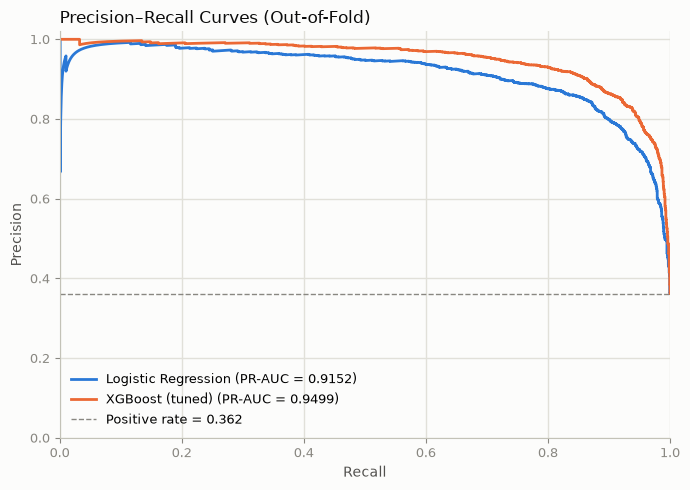

In [68]:
# ---- Figure 1: Out-of-fold Precision-Recall curves ----

SURFACE, INK, INK2, MUTED, GRID, AXIS = (
    "#fcfcfb", "#0b0b0b", "#52514e",
    "#898781", "#e1e0d9", "#c3c2b7"
)

C_LR, C_XGB = "#2a78d6", "#eb6834"

models = [
    ("Logistic Regression", lr_oof, C_LR),
    ("XGBoost (tuned)", xgb_oof, C_XGB)
]

fig, ax = plt.subplots(figsize=(7, 5), facecolor=SURFACE)

ax.set_facecolor(SURFACE)

for s in ("top", "right"):
    ax.spines[s].set_visible(False)

for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS)

ax.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, labelsize=9)

# Plot PR curve for each model
for name, p, color in models:
    precision, recall, _ = precision_recall_curve(y_train, p)
    pr_auc = auc(recall, precision)

    ax.plot(
        recall, precision,
        color=color,
        linewidth=2,
        label=f"{name} (PR-AUC = {pr_auc:.4f})"
    )

# Positive-class prevalence reference
baseline = y_train.mean()
ax.axhline(
    baseline,
    color=MUTED,
    linewidth=1,
    linestyle="--",
    label=f"Positive rate = {baseline:.3f}"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel("Recall", color=INK2)
ax.set_ylabel("Precision", color=INK2)
ax.set_title(
    "Precision–Recall Curves (Out-of-Fold)",
    loc="left",
    fontsize=12,
    color=INK
)

ax.legend(frameon=False, fontsize=9, loc="lower left")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig(
    "figures/pr_curves_oof.png",
    dpi=200,
    bbox_inches="tight",
    facecolor=SURFACE
)

plt.show()


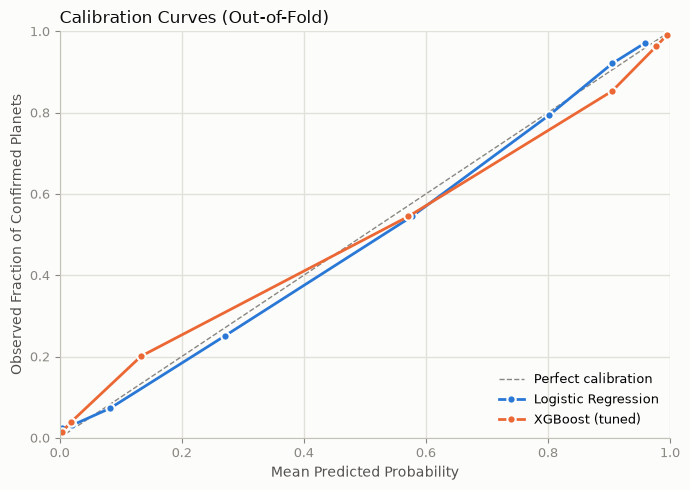

In [69]:
# ---- Figure 2: Out-of-fold Calibration Curves ----
fig, ax = plt.subplots(figsize=(7, 5), facecolor=SURFACE)

ax.set_facecolor(SURFACE)

for s in ("top", "right"):
    ax.spines[s].set_visible(False)

for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS)

ax.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, labelsize=9)

# Perfect calibration reference line
ax.plot(
    [0, 1], [0, 1],
    color=MUTED,
    linewidth=1,
    linestyle="--",
    label="Perfect calibration"
)

# Plot calibration curve for each model
for name, p, color in models:
    frac_pos, mean_pred = calibration_curve(
        y_train, p,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        mean_pred, frac_pos,
        color=color,
        linewidth=2,
        marker="o",
        markersize=6,
        markeredgecolor=SURFACE,
        markeredgewidth=1.5,
        label=name
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel("Mean Predicted Probability", color=INK2)
ax.set_ylabel("Observed Fraction of Confirmed Planets", color=INK2)
ax.set_title(
    "Calibration Curves (Out-of-Fold)",
    loc="left",
    fontsize=12,
    color=INK
)

ax.legend(frameon=False, fontsize=9, loc="lower right")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig(
    "figures/calibration_curves_oof.png",
    dpi=200,
    bbox_inches="tight",
    facecolor=SURFACE
)

plt.show()


# 8. Comparison with the Extended Feature Set

To investigate the effect of feature selection, we compare our conservative 26-feature screening model with an extended 95-feature model.

The extended model excludes explicit target-related variables but includes additional catalog measurements, such as derived planetary parameters and advanced diagnostics.

The comparison helps quantify how much predictive performance changes when these additional measurements are included.

| Model | 26 features (CV PR-AUC) | 95 features (CV PR-AUC) | Difference |
|:--|--:|--:|--:|
| Logistic Regression | 0.915 | ≈ 0.989 | +0.074 |
| XGBoost | 0.950 | ≈ 0.994 | +0.044 |

*The values are rounded results from earlier experiments, not recalculated in this notebook. Comparability assumes the same development split, grouped cross-validation folds, positive class, and PR-AUC calculation.*

The extended models achieve higher cross-validation PR-AUC, suggesting that the additional catalog features contain predictive information. **This performance difference alone does not establish data leakage:** some excluded features may be legitimate measurements available during later vetting. The 26-feature model is retained as the primary early-screening experiment because it avoids many features whose availability at that stage is uncertain. Even this conservative subset is not guaranteed to be historically time-aligned, because the cumulative catalog may contain refined measurements.

# 9: Error Analysis

In [70]:

def analyze_errors(name, probabilities):
    df = X_train.copy()
    df["true_label"] = y_train
    df["predicted_label"] = (probabilities >= 0.5).astype(int)

    conditions = [
        (df["true_label"] == 1) & (df["predicted_label"] == 1),
        (df["true_label"] == 0) & (df["predicted_label"] == 0),
        (df["true_label"] == 0) & (df["predicted_label"] == 1),
        (df["true_label"] == 1) & (df["predicted_label"] == 0)
    ]

    df["outcome"] = np.select(
        conditions,
        ["TP", "TN", "FP", "FN"],
        default="Unknown"
    )

    print(f"\n{name}")
    display(df["outcome"].value_counts())

    cols = [
        "koi_model_snr",
        "koi_depth",
        "koi_duration",
        "koi_period"
    ]

    display(df.groupby("outcome")[cols].median().round(3))

    return df


lr_errors = analyze_errors("Logistic Regression", lr_oof)
xgb_errors = analyze_errors("XGBoost", xgb_oof)



Logistic Regression


outcome
TN    3513
TP    1914
FP     357
FN     284
Name: count, dtype: int64

,koi_model_snr,koi_depth,koi_duration,koi_period
outcome,,,,
FN,22.15,379.20,2.828,4.324
FP,27.60,400.90,3.113,8.870
TN,35.80,676.25,4.255,5.074
TP,29.30,457.95,3.574,12.413



XGBoost


outcome
TN    3606
TP    1944
FP     264
FN     254
Name: count, dtype: int64

,koi_model_snr,koi_depth,koi_duration,koi_period
outcome,,,,
FN,24.45,401.55,2.995,6.942
FP,26.05,417.70,3.079,9.076
TN,36.00,641.10,4.163,5.244
TP,28.95,451.40,3.543,12.001


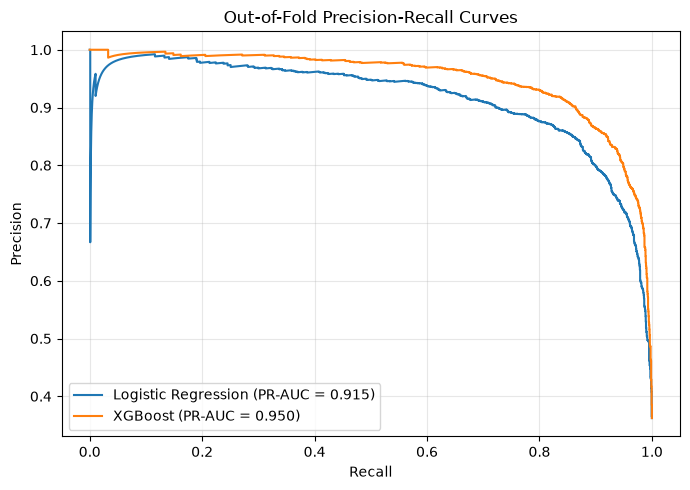

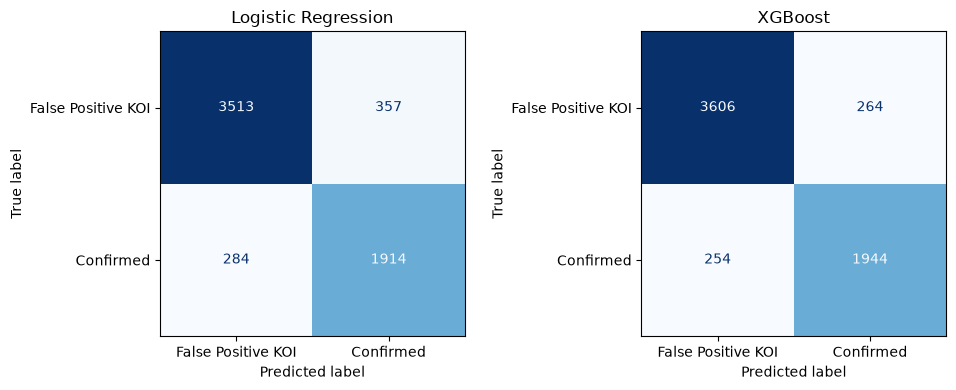

In [71]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

models = {
    "Logistic Regression": lr_oof,
    "XGBoost": xgb_oof
}

# Precision-Recall curves
plt.figure(figsize=(7, 5))

for name, probabilities in models.items():
    precision, recall, _ = precision_recall_curve(
        y_train, probabilities
    )
    pr_auc = auc(recall, precision)

    plt.plot(
        recall, precision,
        label=f"{name} (PR-AUC = {pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-Fold Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, probabilities) in zip(axes, models.items()):
    predictions = (probabilities >= 0.5).astype(int)
    cm = confusion_matrix(y_train, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["False Positive KOI", "Confirmed"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import pandas as pd

def analyze_model_errors(name, probabilities):
    df = X_train.copy()
    df["true_label"] = np.asarray(y_train)
    df["predicted_probability"] = probabilities
    df["predicted_label"] = (probabilities >= 0.5).astype(int)

    y = df["true_label"]
    pred = df["predicted_label"]

    df["outcome"] = np.select(
        [
            (y == 1) & (pred == 1),
            (y == 0) & (pred == 0),
            (y == 0) & (pred == 1),
            (y == 1) & (pred == 0)
        ],
        ["TP", "TN", "FP", "FN"],
        default="Unknown"
    )

    print(f"\n{name}: prediction outcomes")
    display(df["outcome"].value_counts())

    # 1. Weak signals and transit characteristics
    signal_cols = [
        "koi_model_snr",
        "koi_depth",
        "koi_duration",
        "koi_period"
    ]

    print("\nSignal and transit characteristics:")
    display(
        df.groupby("outcome")[signal_cols]
          .median()
          .round(3)
    )

    # 2. Missing measurements
    df["missing_count"] = X_train.isna().sum(axis=1).to_numpy()

    print("\nMissing measurements:")
    display(
        df.groupby("outcome")["missing_count"]
          .agg(["mean", "median"])
          .round(2)
    )

    # 3. Stellar brightness and sky position
    star_cols = [
        c for c in ["koi_kepmag", "koi_gmag", "ra", "dec"]
        if c in df.columns
    ]

    print("\nStellar characteristics:")
    display(
        df.groupby("outcome")[star_cols]
          .median()
          .round(3)
    )

    # 4. False positives confidently predicted as planets
    print("\nMost confident false-positive errors:")
    display(
        df[df["outcome"] == "FP"]
          .sort_values("predicted_probability", ascending=False)
          [["predicted_probability"] + signal_cols]
          .head(10)
    )

    return df


lr_errors = analyze_model_errors(
    "Logistic Regression", lr_oof
)

xgb_errors = analyze_model_errors(
    "XGBoost", xgb_oof
)



Logistic Regression: prediction outcomes


outcome
TN    3513
TP    1914
FP     357
FN     284
Name: count, dtype: int64


Signal and transit characteristics:


,koi_model_snr,koi_depth,koi_duration,koi_period
outcome,,,,
FN,22.15,379.20,2.828,4.324
FP,27.60,400.90,3.113,8.870
TN,35.80,676.25,4.255,5.074
TP,29.30,457.95,3.574,12.413



Missing measurements:


,mean,median
outcome,,
FN,0.32,0.0
FP,0.12,0.0
TN,1.29,0.0
TP,0.05,0.0


... (10 outputs left out)


Stellar characteristics:


,koi_kepmag,koi_gmag,ra,dec
outcome,,,,
FN,14.558,15.140,293.246,43.295
FP,14.378,14.956,292.924,43.806
TN,14.372,14.930,292.943,42.936
TP,14.598,15.144,291.159,44.396



Most confident false-positive errors:


,predicted_probability,koi_model_snr,koi_depth,koi_duration,koi_period
2457,0.998057,46.7,138.5,6.4185,7.033801
1986,0.994822,49.1,272.7,2.5207,6.717256
4022,0.994399,24.9,243.4,1.6208,9.065573
4025,0.993870,37.6,161.1,13.8770,15.745559
2578,0.992300,41.7,452.8,3.9125,6.971069
2144,0.989037,14.6,196.3,4.1170,13.655096
4066,0.987087,48.2,498.0,5.2820,110.921589
1419,0.985944,20.5,101.5,1.3705,2.392631
2018,0.985336,44.1,935.1,3.1408,8.973500
1621,0.984672,19.9,1282.6,3.7260,50.571581


Experimenting with simpler XGBoost models

In [ ]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, auc
import pandas as pd
import numpy as np
import time

# Current tuned configuration
base_params = xgb_best.copy()

# Simpler alternatives
experiments = {
    "Current XGBoost": {},

    "Depth 4": {
        "model__max_depth": 4
    },

    "Depth 3": {
        "model__max_depth": 3
    },

    "Fewer trees (200)": {
        "model__n_estimators": 200
    },

    "Stronger regularization": {
        "model__reg_alpha": 1.0,
        "model__reg_lambda": 5.0
    },

    "Higher min_child_weight": {
        "model__min_child_weight": 10
    },

    "Combined simpler model": {
        "model__max_depth": 3,
        "model__n_estimators": 200,
        "model__reg_alpha": 1.0,
        "model__reg_lambda": 5.0
    }
}

def calculate_pr_auc(y_true, probabilities):
    precision, recall, _ = precision_recall_curve(
        y_true, probabilities
    )
    return auc(recall, precision)

results = []

for name, changes in experiments.items():
    params = base_params.copy()
    params.update(changes)

    train_scores = []
    val_scores = []
    fit_times = []

    for tr, va in folds:
        model = make_xgb_pipeline().set_params(**params)

        start = time.perf_counter()

        model.fit(
            X_train.iloc[tr],
            y_train[tr]
        )

        fit_times.append(time.perf_counter() - start)

        train_probs = model.predict_proba(
            X_train.iloc[tr]
        )[:, 1]

        val_probs = model.predict_proba(
            X_train.iloc[va]
        )[:, 1]

        train_scores.append(
            calculate_pr_auc(y_train[tr], train_probs)
        )

        val_scores.append(
            calculate_pr_auc(y_train[va], val_probs)
        )

    results.append({
        "Model": name,
        "Train PR-AUC": np.mean(train_scores),
        "Validation PR-AUC": np.mean(val_scores),
        "Validation SD": np.std(val_scores, ddof=1),
        "Train-Val Gap": (
            np.mean(train_scores) - np.mean(val_scores)
        ),
        "Training Time (s)": np.mean(fit_times)
    })

complexity_results = pd.DataFrame(results)

display(
    complexity_results.sort_values(
        "Validation PR-AUC", ascending=False
    ).round(4)
)


,Model,Train PR-AUC,Validation PR-AUC,Validation SD,Train-Val Gap,Training Time (s)
1,Depth 4,0.9997,0.9510,0.0070,0.0487,1.6592
2,Depth 3,0.9952,0.9509,0.0028,0.0443,1.1468
0,Current XGBoost,1.0000,0.9502,0.0041,0.0498,1.7954
4,Stronger regularization,0.9984,0.9495,0.0041,0.0489,1.8632
3,Fewer trees (200),0.9997,0.9491,0.0045,0.0506,1.0717
5,Higher min_child_weight,0.9984,0.9472,0.0036,0.0512,1.4957
6,Combined simpler model,0.9720,0.9390,0.0059,0.0330,0.5515
